# From Static Portfolio Optimization to Dynamic Portfolio Management

**Learning goal:** Discover how a portfolio optimized with historical data behaves in new market environments—and what periodic rebalancing changes.

We compare four **long-only** strategies: equal weight (EW), global minimum variance (GMV), maximum expected return for a risk limit (Target Risk), and minimum variance for a return target (Target Return).

**Three steps:** in-sample fit → out-of-sample evaluation → quarterly rebalancing. Some cells are short student exercises.

## 1. Data: daily prices, daily returns

We use 12 US stocks across sectors. Training is **2015–2018**. We then examine **2019 (pre-pandemic)** and **2020 (pandemic shock)** separately. Finally, we evaluate dynamic policies in **2021–2024**.

All performance comparisons use the same stocks. The 2019 environment is *not assumed* to be statistically identical to training: we will check how similar it actually is.

In [1]:
# Run once if these packages are not installed:
# %pip install -q yfinance cvxpy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import cvxpy as cp



In [2]:
ASSETS = ['AAPL','MSFT','JPM','JNJ','XOM','PG','KO','CAT','MCD','WMT','VZ','HD']


prices = yf.download(ASSETS, start='2014-12-01', end='2025-01-01',
                     auto_adjust=True, progress=False)['Close']
prices = prices.loc[:, prices.isna().mean() <= 0.10].dropna()
assets = prices.columns.tolist()
log_daily = np.log(prices).diff().dropna()
print('Assets:', assets, '| Daily observations:', len(prices))

Assets: ['AAPL', 'CAT', 'HD', 'JNJ', 'JPM', 'KO', 'MCD', 'MSFT', 'PG', 'VZ', 'WMT', 'XOM'] | Daily observations: 2538



## EXERCISE 1. Portfolio Optimization: In-Sample (2015–2018)

Using **daily returns from 2015 to 2018**, calculate the optimal weights for the following four portfolios:

1. **Equal Weight (EW):** Invest the same proportion in each asset.
2. **Global Minimum Variance (GMV):** Find the portfolio with the lowest volatility.
3. **Target Risk:** Maximize expected return subject to an **annual volatility limit of 12%**.
4. **Target Return:** Minimize volatility subject to a **minimum expected annual return of 16%**.

### Investment Constraints

- Short selling is not allowed.
- Portfolio weights must sum to 100%.

Use **logarithmic returns** to estimate expected returns and the covariance matrix, and annualize both.

**Tasks:**
- Calculate the weights of the four portfolios using CVXPY.
- Report their expected annual returns and volatilities.
- Compare their compositions and explain the financial differences between the strategies.


VARIABLE NAMING: Use the following variable names for the four portfolios:
- `returns_is` for in-sample expected daily returns
- `weights_ew` for Equal Weight
- `weights_gmv` for Global Minimum Variance
- `weights_target_risk` for Target Risk
- `weights_target_return` for Target Return
- `returns_ew`, `returns_gmv`, `returns_target_risk`, `returns_target_return` for their expected annual returns
- `vols_ew`, `vols_gmv`, `vols_target_risk`, `vols_target_return` for their expected annual volatilities


In [3]:
# TO-DO

In [ ]:
# Portfolio weights DataFrame
portfolio_weights = pd.DataFrame({
    'EW': weights_ew,
    'GMV': weights_gmv,
    'Target Risk': weights_target_risk,
    'Target Return': weights_target_return
}, index=assets)

display(portfolio_weights.style.format('{:.2%}'))

## 3. In-sample performance: does the past look convincing?

We apply the estimated weights **to the same observations used to choose them**. This is deliberately an optimistic, descriptive exercise: **not an investable backtest**. We assume monthly rebalancing to the chosen weights, so each month's portfolio *simple* return is the weighted sum of asset simple returns.

In [9]:
# In-sample portfolio log returns (2015–2018)
portfolio_is = returns_is @ portfolio_weights

# Annualized in-sample returns and volatilities
is_stats = pd.DataFrame({
    'Expected Return': portfolio_is.mean() * 252,
    'Volatility': portfolio_is.std() * np.sqrt(252)
})

display(is_stats.style.format('{:.2%}'))

,Expected Return,Volatility
EW,9.90%,12.85%
GMV,7.74%,11.39%
Target Risk,12.29%,12.00%
Target Return,16.00%,13.51%


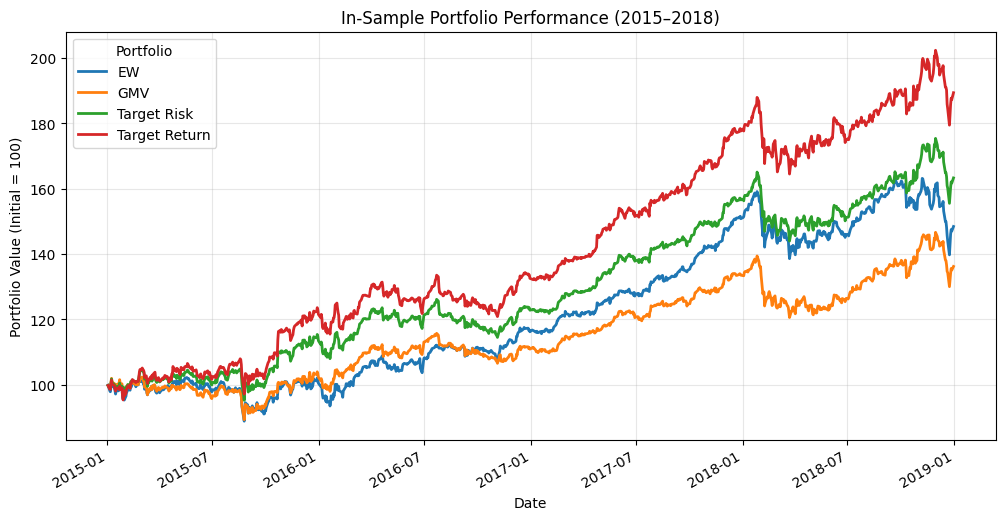

In [10]:
# Portfolio values starting at 100
values_is = 100 * np.exp(portfolio_is.cumsum())

# Plot
plt.figure(figsize=(12, 6))

values_is.plot(ax=plt.gca(), linewidth=2)

plt.title('In-Sample Portfolio Performance (2015–2018)')
plt.xlabel('Date')
plt.ylabel('Portfolio Value (Initial = 100)')
plt.grid(alpha=0.3)
plt.legend(title='Portfolio')

plt.show()


## 4. Out-of-Sample Evaluation: Do Our Portfolios Perform Well in the Future?

We have constructed four portfolios using historical data from **2015–2018**: Equal Weight (EW), Global Minimum Variance (GMV), Target Risk and Target Return.

**Our objective is to evaluate whether portfolios optimized using historical information maintain their performance in future market conditions.**

### Exercise

**1. Evaluate portfolio performance in 2019 and 2020**

Using the portfolio weights calculated from 2015–2018:

- Evaluate the four portfolios during **2019** and **2020**, without changing their original weights.
- Calculate their annualized mean returns and volatilities for each period.
- Plot the evolution of an initial investment of €100 in each portfolio, separately for 2019 and 2020.

**2. Compare in-sample and out-of-sample performance**

- Create a summary table showing the annualized mean returns and volatilities of the four portfolios for **2015–2018, 2019 and 2020**.
- Create two bar charts comparing portfolio returns and volatilities across the three periods.

**3. Analyze changes in individual assets**

For each asset:

- Calculate its annualized mean return and volatility in the three periods.
- Create two bar charts comparing individual asset returns and volatilities across periods.

**4. Analyze changes in correlations**

- Calculate the correlation matrices for **2015–2018, 2019 and 2020**.
- Display the three matrices using heatmaps with a common color scale.

### 5. Financial Discussion

Based on your results, answer the following questions:

1. Which portfolio performed best in-sample? Did it also perform best in 2019 and 2020?
2. How did portfolio returns and volatilities change across the three periods?
3. Did the Target Risk portfolio maintain its original volatility limit out-of-sample?
4. How did individual asset returns, volatilities and correlations change?
5. How might these changes explain the differences between in-sample and out-of-sample portfolio performance?

**Final question:** What do these results tell us about the limitations of constructing portfolios using historical estimates?


Variable Naming: Use the following variable names for the four portfolios:
- `returns_oos_2019` for out-of-sample expected daily returns in 2019
- `returns_oos_2020` for out-of-sample expected daily returns in 2020
- `portfolio_returns_2019` for portfolio returns in 2019
- `portfolio_returns_2020` for portfolio returns in 2020
- `value_2019` for portfolio value in 2019
- `value_2020` for portfolio value in 2020

In [ ]:
# TO-DO

### Per period individual seets analysis

In [ ]:
# TO DO



## 5. Monthly Portfolio Reoptimization (2021–2024)

Until now, we have calculated portfolio weights using historical data and evaluated their performance in subsequent periods without updating them.

**But market conditions change. Should we continue using the same portfolio weights?**

We will now implement a **monthly portfolio reoptimization strategy**:

1. Use the previous **48 months of daily returns** to estimate expected returns and covariances.
2. Recalculate the optimal weights of our four portfolios: EW, GMV, Target Risk and Target Return.
3. Invest using these weights during the following month.
4. Move the estimation window forward by one month and repeat the process.

### Investment Mandates

We will keep the investment objectives **fixed throughout the entire period**:

- **EW:** Equal weights across all assets.
- **GMV:** Minimize portfolio variance.
- **Target Risk:** Maximize expected return with a maximum annual volatility of **12%**.
- **Target Return:** Minimize variance with a minimum expected annual return of **16%**.

If a target becomes infeasible, we will apply our predefined fallback rules and record when this happens.

**Investment period:** January 2021 – December 2024.

**Key idea:** We are not restoring the original portfolio weights. We are **recalculating optimal weights every month using updated market information**, while keeping the investment objectives unchanged.



In [18]:

def calculate_weights(mu, Sigma, strategy, target_vol=0.12, target_return=0.16):
    """
    Calculate optimal portfolio weights using CVXPY.

    Parameters
    ----------
    mu : numpy.ndarray
        Expected daily log returns for each asset.
    Sigma : numpy.ndarray
        Daily covariance matrix of asset log returns.
    strategy : str
        Portfolio strategy: 'EW', 'GMV', 'Target Risk', or 'Target Return'.
    target_vol : float
        Maximum annual volatility for the Target Risk strategy.
    target_return : float
        Minimum annual expected log return for the Target Return strategy.

    Returns
    -------
    numpy.ndarray or None
        Optimal portfolio weights, normalized to sum to 1.
        Returns None if no solution is found.

    Notes
    -----
    - Long-only portfolios with weights summing to 1.
    - Annual targets are converted to daily frequency (252 trading days).
    - Markowitz optimization is applied to daily logarithmic returns.
    """

    N = len(mu)

    # Equal Weight
    if strategy == 'EW':
        return np.ones(N) / N

    # Decision variable
    w = cp.Variable(N)

    # Common constraints
    constraints = [
        cp.sum(w) == 1,
        w >= 0
    ]

    # Global Minimum Variance
    if strategy == 'GMV':
        objective = cp.Minimize(cp.quad_form(w, Sigma))

    # Maximum Return with Target Risk
    elif strategy == 'Target Risk':
        target_vol_daily = target_vol / np.sqrt(252)

        constraints += [
            cp.quad_form(w, Sigma) <= target_vol_daily**2
        ]

        objective = cp.Maximize(mu @ w)

    # Minimum Risk with Target Return
    elif strategy == 'Target Return':
        target_return_daily = target_return / 252

        constraints += [
            mu @ w >= target_return_daily
        ]

        objective = cp.Minimize(cp.quad_form(w, Sigma))

    # Solve optimization problem
    problem = cp.Problem(objective, constraints)
    problem.solve(solver=cp.CLARABEL)

    # Return None if no solution is found
    if w.value is None:
        return None

    # Remove negligible weights and normalize
    weights = np.array([x if x >= 1e-4 else 0 for x in w.value])
    return weights / weights.sum()



### 5.1 First Reoptimization: January 2021

Imagine that today is December 31, 2020.

We want to construct our portfolios for January 2021.

- **Estimation window:** January 2017 – December 2020.
- **Investment period:** January 2021.

We calculate the four portfolio weights using historical information and then evaluate their performance during January 2021.

**Important:** January 2021 returns cannot be used to calculate the weights.


In [19]:
TARGET_RISK= 0.12
TARGET_RETURN = 0.25

In [2]:

# Estimation window: four years of daily returns
train = log_daily.loc['2017':'2020']

# Estimate daily expected returns and covariance matrix
mu = train.mean().to_numpy()
Sigma = train.cov().to_numpy()

# Calculate the four portfolios
strategies = ['EW', 'GMV', 'Target Risk', 'Target Return']

weights_jan = pd.DataFrame({
    strategy: calculate_weights(mu, Sigma, strategy,
                                target_vol=TARGET_RISK,
                                target_return=TARGET_RETURN)
    for strategy in strategies
}, index=assets)

display(weights_jan.style.format('{:.2%}'))


NameError: name 'log_daily' is not defined

In [31]:
weights_jan

,EW,GMV,Target Risk,Target Return
AAPL,0.083333,0.000146,0.000146,0.093951
CAT,0.083333,0.000000,0.000000,0.000000
HD,0.083333,0.000000,0.000000,0.000000
JNJ,0.083333,0.164285,0.164285,0.110959
JPM,0.083333,0.000000,0.000000,0.000000
KO,0.083333,0.130254,0.130254,0.092703
MCD,0.083333,0.130616,0.130616,0.131061
MSFT,0.083333,0.000000,0.000000,0.000000
PG,0.083333,0.064620,0.064620,0.086836
VZ,0.083333,0.308064,0.308064,0.241898


In [32]:
vol_gmv = np.sqrt(weights_jan['GMV'] @ Sigma @ weights_jan['GMV'])

print(f"GMV annual volatility: {vol_gmv * np.sqrt(252):.2%}")
print("Client's volatility limit: 14.00%")

GMV annual volatility: 12.32%
Client's volatility limit: 14.00%


MODIFY TARGET_RISK

In [41]:
TARGET_RISK = 0.25

In [42]:

def calculate_weights_dynamic(mu, Sigma, strategy, target_vol=0.12, target_return=0.16):
    """
    Calculate portfolio weights, handling infeasible investment mandates.

    Parameters
    ----------
    mu : numpy.ndarray
        Expected daily log returns.
    Sigma : numpy.ndarray
        Daily covariance matrix.
    strategy : str
        'EW', 'GMV', 'Target Risk', or 'Target Return'.
    target_vol : float
        Maximum annual portfolio volatility.
    target_return : float
        Minimum annual expected log return.

    Returns
    -------
    weights : numpy.ndarray
        Portfolio weights summing to 1.
    fallback : bool
        True if an alternative portfolio was used.

    Notes
    -----
    If Target Risk is infeasible, use the GMV portfolio.
    If Target Return is infeasible, invest in the asset with
    the highest expected return.
    """

    # First, try to satisfy the original investment mandate
    weights = calculate_weights(mu, Sigma, strategy, target_vol, target_return)

    # If the optimization is feasible, return the optimal weights
    if weights is not None:
        return weights, False

    # Target Risk: use the Global Minimum Variance portfolio
    if strategy == 'Target Risk':
        weights = calculate_weights(mu, Sigma, 'GMV')
        return weights, True

    # Target Return: invest in the asset with the highest expected return
    if strategy == 'Target Return':
        weights = np.zeros(len(mu))
        weights[np.argmax(mu)] = 1
        return weights, True

    raise RuntimeError(f"Optimization failed for {strategy}")


In [43]:
# Estimation window: four years of daily returns
train = log_daily.loc['2017':'2020']

# Estimate daily expected returns and covariance matrix
mu = train.mean().to_numpy()
Sigma = train.cov().to_numpy()

# Calculate the four portfolios
strategies = ['EW', 'GMV', 'Target Risk', 'Target Return']

solutions = {
    strategy: calculate_weights_dynamic(mu, Sigma, strategy)
    for strategy in strategies
}

# Extract portfolio weights
weights_jan = pd.DataFrame({
    strategy: solutions[strategy][0]
    for strategy in strategies
}, index=assets)

# Identify strategies that required a fallback
fallback_jan = {
    strategy: solutions[strategy][1]
    for strategy in strategies
}

display(weights_jan.style.format('{:.2%}'))
print("Fallbacks used:", fallback_jan)


,EW,GMV,Target Risk,Target Return
AAPL,8.33%,0.01%,0.01%,9.40%
CAT,8.33%,0.00%,0.00%,0.00%
HD,8.33%,0.00%,0.00%,0.00%
JNJ,8.33%,16.43%,16.43%,11.10%
JPM,8.33%,0.00%,0.00%,0.00%
KO,8.33%,13.03%,13.03%,9.27%
MCD,8.33%,13.06%,13.06%,13.11%
MSFT,8.33%,0.00%,0.00%,0.00%
PG,8.33%,6.46%,6.46%,8.68%
VZ,8.33%,30.81%,30.81%,24.19%


Fallbacks used: {'EW': False, 'GMV': False, 'Target Risk': True, 'Target Return': False}



### 5.2 Portfolio Performance: January 2021

#### **EJERCICIO**

We have calculated the portfolio weights using information available at the end of December 2020.

**Now we invest during January 2021 without changing the weights.**

Our objective is to evaluate the performance of the four portfolios using January's daily returns.

**Question:** Which strategy achieved the highest return during January?


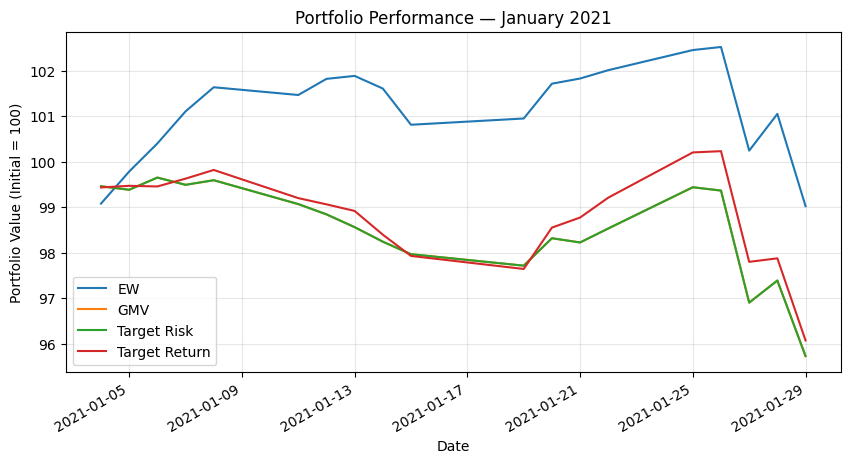

,January Return
EW,-0.98%
GMV,-4.27%
Target Risk,-4.27%
Target Return,-3.93%


In [44]:

# Daily log returns for January 2021
returns_jan = log_daily.loc['2021-01']

# Portfolio log returns
portfolio_jan = returns_jan @ weights_jan

# Portfolio values starting at 100
values_jan = 100 * np.exp(portfolio_jan.cumsum())

# Plot portfolio evolution
values_jan.plot(figsize=(10, 5))

plt.title('Portfolio Performance — January 2021')
plt.ylabel('Portfolio Value (Initial = 100)')
plt.grid(alpha=0.3)
plt.show()

# January cumulative returns
jan_returns = np.exp(portfolio_jan.sum()) - 1

display(jan_returns.to_frame('January Return').style.format('{:.2%}'))



### 5.3 Exercise: Reoptimizing the Portfolios for February 2021

It is now January 31, 2021. One additional month of market information is available.

**Your task is to calculate the optimal portfolios for February 2021.**

1. Move the estimation window forward by one month: February 2017 – January 2021.
2. Estimate daily expected returns and the covariance matrix.
3. Calculate the four portfolios using `calculate_weights_dynamic()`.
4. Evaluate their performance during February 2021.
5. Compare January and February portfolio weights.

**Questions:**

- Which portfolio changed its weights the most?
- Did any strategy require a fallback?
- Why do optimal weights change even though the investment mandate remains unchanged?


In [45]:

# # 1. Select the new estimation window
# train_feb = log_daily.loc['2017-02':'2021-01']

# # 2. Estimate expected returns and covariance matrix
# mu_feb = ...
# Sigma_feb = ...

# # 3. Calculate portfolio weights
# solutions_feb = ...

# # 4. Build the weights DataFrame
# weights_feb = ...

# # 5. Evaluate February performance
# returns_feb = log_daily.loc['2021-02']
# portfolio_feb = ...

# # 6. Compare portfolio weights
# display(weights_feb - weights_jan)




### 5.4 Automating Monthly Portfolio Reoptimization

#### EXERCISE

Until now, we have calculated portfolio weights for individual months. Your challenge is to **implement a dynamic portfolio management strategy from January 2021 to December 2024**.

The objective is to evaluate how our four portfolio strategies perform when their optimal weights are updated every month.

### Investment Rules

- **Estimation window:** Previous 48 months of daily returns.
- **Reoptimization frequency:** Monthly.
- **Investment period:** January 2021 – December 2024.
- **Strategies:** EW, GMV, Target Risk and Target Return.
- **Investment constraints:** No short selling; portfolio weights must sum to 100%.
- **Investment targets:** Use the previously defined `TARGET_RISK` and `TARGET_RETURN`.
- **Infeasible portfolios:** Apply the fallback rules established in the previous exercise.

### Tasks

**1. Dynamic portfolio construction**

Calculate the optimal weights of the four portfolios for every month in the investment period, using only information available before each investment decision.

**2. Portfolio performance**

- Calculate the daily returns of each portfolio throughout 2021–2024.
- Calculate and plot the evolution of an initial investment of €100 in each strategy.
- Report the annualized mean returns and volatilities.

**3. Portfolio composition and feasibility**

- Record the portfolio weights obtained at each monthly reoptimization.
- Identify how many months each strategy required a fallback solution.

### Financial Discussion

1. Which strategy achieved the highest return and which had the lowest volatility?
2. Did the optimal portfolio weights remain stable over time?
3. How frequently were the Target Risk and Target Return mandates infeasible?
4. Does monthly reoptimization guarantee better investment performance?

**Key question:** How does periodically updating portfolio decisions affect the risk and performance of an investment strategy?



In [ ]:
#TO DO

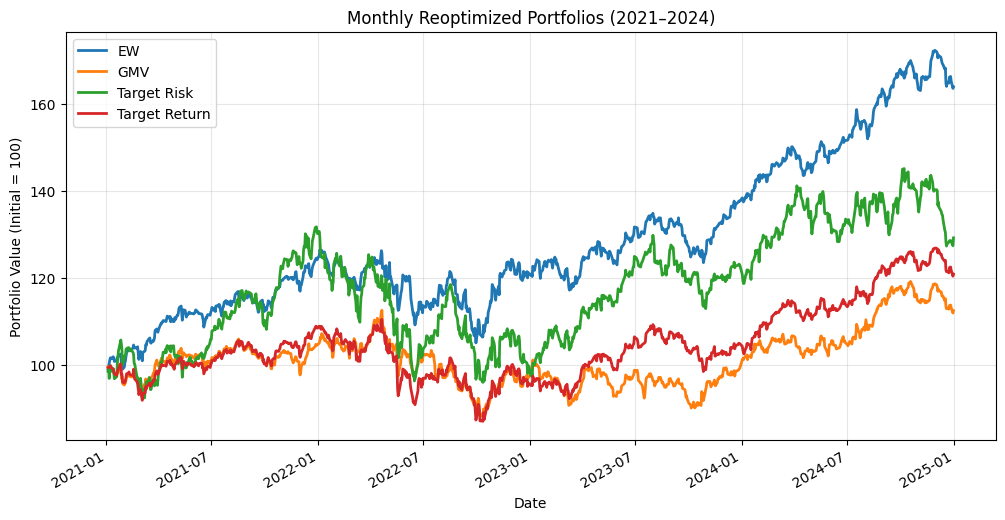

,Annualized Return,Annualized Volatility
EW,12.41%,12.71%
GMV,2.95%,12.34%
Target Risk,6.44%,19.19%
Target Return,4.76%,12.75%


In [47]:

# Portfolio values starting at 100
dynamic_values = 100 * np.exp(dynamic_returns.cumsum())

# Plot portfolio evolution
dynamic_values.plot(figsize=(12, 6), linewidth=2)

plt.title('Monthly Reoptimized Portfolios (2021–2024)')
plt.xlabel('Date')
plt.ylabel('Portfolio Value (Initial = 100)')
plt.grid(alpha=0.3)
plt.show()

# Annualized portfolio statistics
dynamic_stats = pd.DataFrame({
    'Annualized Return': dynamic_returns.mean() * 252,
    'Annualized Volatility': dynamic_returns.std() * np.sqrt(252)
})

display(dynamic_stats.style.format('{:.2%}'))


In [48]:

# Number of months requiring a fallback
fallback_counts = fallback_df.sum()

print("Months requiring fallback:")
display(fallback_counts.to_frame('Number of Months'))


Months requiring fallback:


,Number of Months
EW,0
GMV,0
Target Risk,0
Target Return,0


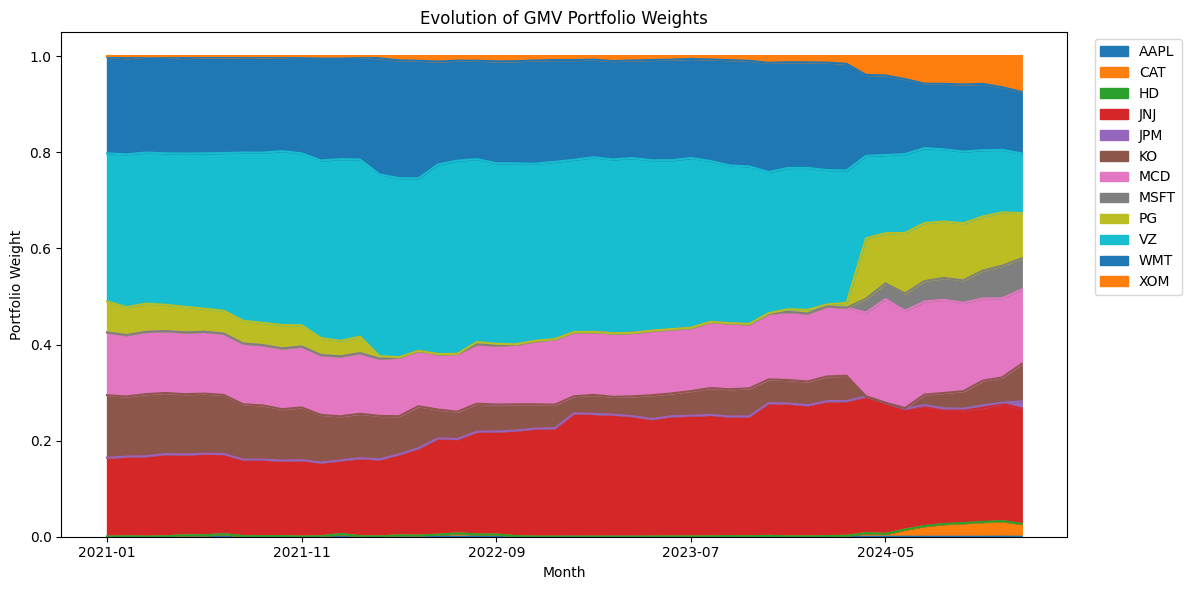

In [49]:

# GMV portfolio weights at each monthly rebalance
gmv_weights = pd.DataFrame({
    month: weights['GMV']
    for month, weights in weights_history.items()
}).T

# Plot evolution of portfolio weights
gmv_weights.plot.area(figsize=(12, 6))

plt.title('Evolution of GMV Portfolio Weights')
plt.xlabel('Month')
plt.ylabel('Portfolio Weight')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()
